# 02 — Baseline: fall or no fall from the depth features

**Goal:** build the simplest possible model that looks at a whole video and answers *fall* or *no fall*.

**Why start here?** A baseline gives us a score to beat. Later (notebook 04) we build a model from skeleton graphs; it is only interesting if we can compare it with something simple.

**Data used:** the label files `urfall-cam0-falls.csv` and `urfall-cam0-adls.csv`. For every frame they contain 8 numbers that the dataset authors computed from the depth camera (the person's shape and height). No images are needed in this notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") / "data" / "raw" / "urfd"
FEATS = ["HeightWidthRatio", "MajorMinorRatio", "BBoxOccupancy", "MaxStdXZ", "HHmaxRatio", "H", "D", "P40"]

💡 **Interpretation:** setup only: the libraries, the data folder and the names of the 8 depth features computed by the dataset authors.

## Step 1 — Load the frame table

One row = one frame. Columns: video name, frame number, frame label, then the 8 depth features.
We put both files together. `ignore_index=True` gives every row its own number (both files start at 0, which otherwise causes errors later).

In [2]:
frames = pd.concat(
    [pd.read_csv(ROOT / "labels" / f"urfall-cam0-{kind}.csv", header=None) for kind in ["falls", "adls"]],
    ignore_index=True)
frames.columns = ["video", "frame", "frame_label"] + FEATS
print(frames.shape)
frames.head()

(11544, 11)


,video,frame,frame_label,HeightWidthRatio,MajorMinorRatio,BBoxOccupancy,MaxStdXZ,HHmaxRatio,H,D,P40
0,fall-01,1,-1,3.1667,2.9098,0.55367,126.0258,1.0324,1899.5366,1055.9988,0.047310
1,fall-01,2,-1,3.3067,2.9699,0.47876,125.5657,1.1251,2070.1193,1065.9506,0.048175
2,fall-01,3,-1,3.1408,3.0506,0.54374,123.1570,1.0161,1869.6442,1055.4955,0.050180
3,fall-01,4,-1,3.4306,3.1435,0.48859,124.5614,1.1251,2070.1193,1076.1464,0.047877
4,fall-01,5,-1,3.6324,3.3012,0.49744,123.6089,1.1251,2070.1193,1075.5053,0.052543


💡 **Interpretation:** 11,544 frames from 70 videos: a video is just a sequence of frames (30 per second). `frame_label` (-1 not lying, 0 falling, 1 lying) describes the answer, so the model must **never** see it.

## Step 2 — Look at one feature over time

`HHmaxRatio` compares the person's current height with their maximum height. Over all videos its median is **0.92** when not lying, **0.52** while falling and **0.27** while lying on the floor. Let us plot it for one fall and one daily activity (ADL).

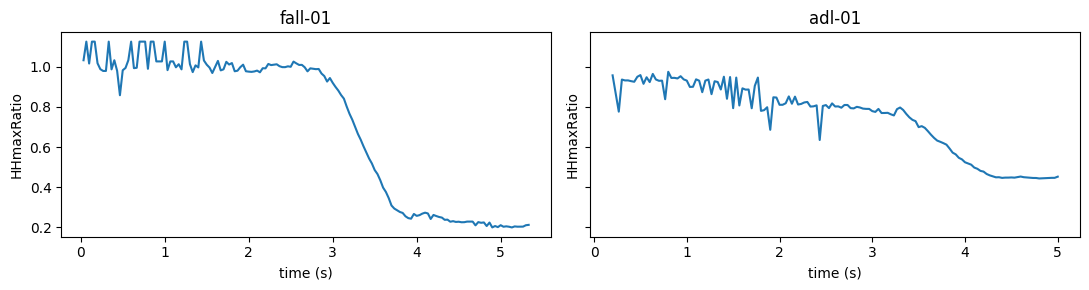

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, video in zip(axes, ["fall-01", "adl-01"]):
    d = frames[frames.video == video]
    ax.plot(d.frame / 30, d.HHmaxRatio)
    ax.set(title=video, xlabel="time (s)", ylabel="HHmaxRatio")
plt.tight_layout(); plt.show()

💡 **Interpretation:** a fall is a **sudden, lasting drop** in height (≈1.0 → ≈0.2, and it stays low). In the daily activity the height moves (bending, sitting) but never reaches floor level (lowest 0.44).

## Step 3 — One row per video

The model needs **one row per video**, but we have one row per frame. So we summarise each feature over the whole video with three numbers: its **mean**, **minimum** and **maximum**.
The answer (target) is simple: videos named `fall-…` are falls (1), videos named `adl-…` are not (0).

In [4]:
videos = frames.groupby("video")[FEATS].agg(["mean", "min", "max"])
videos.columns = [f"{feat}_{stat}" for feat, stat in videos.columns]
y = videos.index.str.startswith("fall").astype(int)

print(videos.shape, "->", y.sum(), "falls and", (y == 0).sum(), "ADLs")
videos.iloc[:3, :6]

(70, 24) -> 30 falls and 40 ADLs


,HeightWidthRatio_mean,HeightWidthRatio_min,HeightWidthRatio_max,MajorMinorRatio_mean,MajorMinorRatio_min,MajorMinorRatio_max
video,,,,,,
adl-01,2.253728,1.0675,6.3214,2.685956,1.2868,8.2230
adl-02,2.154503,1.1497,5.1471,2.335247,1.0342,7.6229
adl-03,2.139074,1.1544,3.8590,2.548504,1.4095,4.8892


💡 **Interpretation:** each video is now **one point described by 24 numbers** (8 features × mean/min/max); e.g. a low minimum height means the person reached the floor. 30 falls vs 40 ADLs is almost balanced, so accuracy stays meaningful.

## Step 4 — Test the model fairly with cross-validation

With only 70 videos, one train/test split would test on very few videos and the score would depend on luck.
**5-fold cross-validation** solves this: split the videos into 5 groups, train on 4 and test on the 5th, and repeat so every video is tested exactly once. *Stratified* means each group keeps the same fall / ADL mix.

The model is a **logistic regression**: it learns one weight per column and outputs the probability of a fall. `StandardScaler` puts all columns on the same scale first, because the features have very different units.

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred = cross_val_predict(model, videos, y, cv=cv)   # each video predicted by a model that never saw it

💡 **Interpretation:** no score yet: every video was predicted by a model trained only on the **other** videos, which imitates real use on new, unseen people.

## Step 5 — How good is it?

- **Accuracy:** share of videos classified correctly.
- **Recall (falls):** of all real falls, how many did we catch? *The most important number*: a missed fall is the worst mistake.
- **Precision (falls):** when we say "fall", how often are we right? Low precision = false alarms.
- **Confusion matrix:** the four counts behind these numbers.

accuracy : 0.957
recall   : 0.967
precision: 0.935


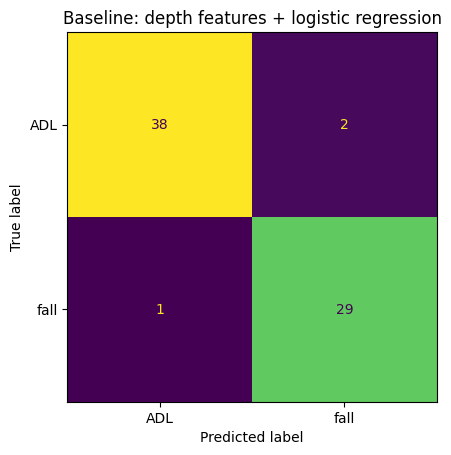

In [6]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, ConfusionMatrixDisplay

print(f"accuracy : {accuracy_score(y, pred):.3f}")
print(f"recall   : {recall_score(y, pred):.3f}")
print(f"precision: {precision_score(y, pred):.3f}")
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["ADL", "fall"], colorbar=False)
plt.title("Baseline: depth features + logistic regression"); plt.show()

💡 **Interpretation:** 67 of 70 videos are right: 29 of 30 falls caught (recall 0.967) and 2 false alarms (precision 0.935). Falls are easy at video level because every fall video **ends with the person on the floor**.

In [7]:
wrong = videos.index[pred != y]
print("misclassified videos:", list(wrong))

misclassified videos: ['adl-35', 'adl-40', 'fall-01']


💡 **Interpretation:** `adl-40` ends **lying down on purpose**, so over the whole video it looks like a fall; `adl-35` also lies down (then gets up). Why `fall-01` is missed is checked in notebook 06.

## What we learned

1. **A simple model already works very well**: 67 of 70 videos are correct (accuracy 0.957), 29 of 30 falls are caught (recall 0.967), with 2 false alarms (`adl-35`, `adl-40`) and 1 missed fall (`fall-01`).
2. This is our **baseline**: the skeleton graph model in notebook 04 must be compared with these numbers.
3. **Honest limit:** every fall video in this dataset ends with the person on the floor, and is short. Summaries over the whole video (like the minimum height) catch that easily, so the task at video level is easier than real-life detection. We mention this in the report.

**Next notebook (03):** extract skeletons (body joints) from the RGB video with MediaPipe.